# Deep Learning Project - Jigsaw puzzle reconstruction

**Student:** Sergio Pascual Redondo  
**Date:** 06-06-2026  
**Task:** reconstruct a 96 x 96 x 3 RGB image from 9 shuffled patches of size 28 x 28 x 3.

The original image is divided into a 3 x 3 grid. Each patch comes from one cell of that grid, but the input order is random and the borders have been removed, so the model has to infer both the approximate location of each patch and the missing seams.

I keep the same input/output format as the assignment: the generator gives the model only the shuffled patches and the full image target. The permutation used to shuffle the patches is not returned and is not used as a label. The model is trained from the reconstruction error measured with MAE.


## Setup

The notebook is prepared for Google Colab. I define the main constants at the beginning, then create the dataset generator, the model, the optional training cell and the final evaluation.

I use the memory-mapped version of STL10 because loading the whole dataset as float32 would use too much RAM. With this approach the data stays as uint8 on disk and each batch is converted and normalized only when it is needed.

For the final submission I leave TRAIN_MODEL as False, so the notebook loads the trained weights with gdown and goes directly to the test evaluation. If I wanted to train the model again, I would change this value to True.


In [ ]:
import os
from pathlib import Path
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from keras.utils import PyDataset
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

# Image Config
HEIGHT = 96
WIDTH = 96
N_CHANNELS = 3
GRID_SIZE = 3
NUM_PATCHES = GRID_SIZE ** 2
PATCH_SIZE = 32
CROP_SIZE = 28

# Training Config
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 5e-4

# Local fallback path used only inside the current Colab runtime.
# The submitted weights are downloaded below with gdown, so no mounted Drive is required.
WEIGHTS_PATH = Path('/content/patch_reconstructor_compliant_attention_final.weights.h5')

# Dataset split and run size
# For quick tests I can lower these values and then restore them for the final run.
TRAIN_LIMIT = 80000
VAL_LIMIT = 10000
BATCH_SIZE = 32
EPOCHS = 60

# False = load weights and evaluate. True = train again.
TRAIN_MODEL = False

# Google Drive URL or file id for the final trained weights.
WEIGHTS_URL_OR_ID = 'https://drive.google.com/file/d/1QtM8X3xJ8UvQT2IOK5pu8nk_pjYdeXam/view?usp=sharing'
# Alternative: paste only the file id here.
WEIGHTS_FILE_ID = '1QtM8X3xJ8UvQT2IOK5pu8nk_pjYdeXam'
GDRIVE_FILE_ID = WEIGHTS_FILE_ID
DOWNLOADED_WEIGHTS_PATH = '/content/submitted_patch_reconstructor.weights.h5'

# Temperature schedule for the soft placement layer.
PLACEMENT_TAU_INITIAL = 2.0
PLACEMENT_TAU_FINAL = 0.3

print(f'TRAIN_LIMIT: {TRAIN_LIMIT}, VAL_LIMIT: {VAL_LIMIT}, BATCH_SIZE: {BATCH_SIZE}, EPOCHS: {EPOCHS}')
print(f'Placement tau: {PLACEMENT_TAU_INITIAL:.1f} -> {PLACEMENT_TAU_FINAL:.1f}')


## Dataset and generator

The dataset is the unlabeled split of STL10. The generator creates batches with:

- X: the 9 shuffled cropped patches, with shape (batch, 9, 28, 28, 3).
- Y: the original image, with shape (batch, 96, 96, 3).

The permutation is only used inside the generator to shuffle the input patches. It is not returned to the model. In this way the network cannot solve the task by reading the correct order directly; it has to learn from the visual information and from the final reconstruction loss.

For training I added simple augmentations: horizontal flip and small brightness/contrast/saturation changes. I only apply them to the training split. Validation and test are kept fixed so the MAE is comparable.


In [3]:
def get_stl10_memmap():
    path = tf.keras.utils.get_file(
        'stl10_binary.tar.gz',
        origin='http://ai.stanford.edu/~acoates/stl10/stl10_binary.tar.gz',
        extract=True,
    )

    base_dir = os.path.dirname(path)
    candidates = [
        os.path.join(base_dir, 'stl10_binary_extracted', 'stl10_binary'),
        os.path.join(base_dir, 'stl10_binary'),
        os.path.join(base_dir, 'datasets', 'stl10_binary'),
    ]

    filepath = None
    for candidate_dir in candidates:
        candidate_path = os.path.join(candidate_dir, 'unlabeled_X.bin')
        if os.path.exists(candidate_path):
            filepath = candidate_path
            break

    if filepath is None:
        raise FileNotFoundError('Could not find STL10 unlabeled_X.bin after extraction.')

    print(f'Using STL10 binary file: {filepath}')
    # STL10 binary format stores images as (N, C, H, W). np.memmap keeps the
    # array on disk and reads samples on demand, which avoids a large RAM copy.
    # The generator converts individual samples to (H, W, C) when needed.
    return np.memmap(filepath, dtype='uint8', mode='r', shape=(100000, N_CHANNELS, HEIGHT, WIDTH))


class PatchGenerator(PyDataset):
    def __init__(self, images_mmap, batch_size=32, patch_size=PATCH_SIZE, crop_size=CROP_SIZE,
                 shuffle=True, augment=False, **kwargs):
        super().__init__(**kwargs)
        self.images = images_mmap
        self.batch_size = batch_size
        self.patch_size = patch_size
        self.crop_size = crop_size
        self.shuffle = shuffle
        self.augment = augment
        self.indices = np.arange(len(self.images))
        self.margin = (self.patch_size - self.crop_size) // 2
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def _augment(self, img):
        """Label-safe augmentation on a float32 HxWx3 image in [0, 1]."""
        if np.random.rand() < 0.5:
            img = img[:, ::-1, :]
        img = img + np.random.uniform(-0.10, 0.10)
        mean = img.mean()
        img = (img - mean) * np.random.uniform(0.85, 1.15) + mean
        lum = (img * np.array([0.299, 0.587, 0.114], dtype=np.float32)).sum(axis=2, keepdims=True)
        img = lum + (img - lum) * np.random.uniform(0.85, 1.15)
        return np.clip(img, 0.0, 1.0).astype(np.float32)

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        actual_batch_size = len(batch_indices)

        # X contains only the 9 shuffled cropped patches.
        # Y is the full original image used for the MAE reconstruction loss.
        X = np.empty((actual_batch_size, NUM_PATCHES, self.crop_size, self.crop_size, N_CHANNELS), dtype=np.float32)
        Y = np.empty((actual_batch_size, HEIGHT, WIDTH, N_CHANNELS), dtype=np.float32)

        for i, img_idx in enumerate(batch_indices):
            # Load one uint8 image, convert channel-first STL10 format to
            # channel-last Keras format, and normalize to [0, 1].
            img_cxhxw = self.images[img_idx]
            full_img = img_cxhxw.transpose(2, 1, 0).astype(np.float32) / 255.0

            if self.augment:
                full_img = self._augment(full_img)

            Y[i] = full_img

            # Extract the 3x3 patches. The external 2-pixel border of each
            # 32x32 cell is removed, leaving 28x28 patches as in the statement.
            patches = []
            for r in range(GRID_SIZE):
                for c in range(GRID_SIZE):
                    y0 = r * self.patch_size + self.margin
                    x0 = c * self.patch_size + self.margin
                    patches.append(full_img[y0 : y0 + self.crop_size, x0 : x0 + self.crop_size, :])

            # Training uses fresh random shuffles to avoid memorizing one order.
            # Validation/test use a fixed deterministic shuffle per image so the
            # reported MAE is reproducible from one execution to another.
            if self.shuffle:
                order = np.random.permutation(NUM_PATCHES)
            else:
                rng = np.random.default_rng(int(img_idx))
                order = rng.permutation(NUM_PATCHES)

            for input_slot, original_pos in enumerate(order):
                X[i, input_slot] = patches[original_pos]

        return X, Y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


def get_image_targets(targets):
    """Return the image target whether targets is a dict or a bare array."""
    return targets['reconstructed_image'] if isinstance(targets, dict) else targets


In [4]:
# Open the STL10 unlabeled split without loading the whole file into RAM.
images = get_stl10_memmap()
print('Dataset shape:', images.shape, 'dtype:', images.dtype)

# Fixed split: training images, validation images and final held-out test images.
train_images = images[:80000]
val_images = images[80000:90000]
test_images = images[90000:]

# Important: train_generator uses only train_images, not the full images array.
train_generator = PatchGenerator(train_images[:TRAIN_LIMIT], batch_size=BATCH_SIZE, shuffle=True, augment=True)
val_generator = PatchGenerator(val_images[:VAL_LIMIT], batch_size=BATCH_SIZE, shuffle=False, augment=False)
test_generator = PatchGenerator(test_images, batch_size=BATCH_SIZE, shuffle=False, augment=False)

print('Train batches:', len(train_generator))
print('Validation batches:', len(val_generator))
print('Test batches:', len(test_generator))


2640397119/2640397119 ━━━━━━━━━━━━━━━━━━━━ 269s 0us/step
Using STL10 binary file: /root/.keras/datasets/stl10_binary_extracted/stl10_binary/unlabeled_X.bin
Dataset shape: (100000, 3, 96, 96) dtype: uint8
Train batches: 2500
Validation batches: 313
Test batches: 313


## Sanity checks

Verify the generator output shapes, dtypes and value ranges. The generator must return only (patches, image); it must not return the numerical permutation.


In [5]:
X_s, Y_s = train_generator[0]

print('X            :', X_s.shape, X_s.dtype, f'[{X_s.min():.3f}, {X_s.max():.3f}]')
print('image target :', Y_s.shape, Y_s.dtype, f'[{Y_s.min():.3f}, {Y_s.max():.3f}]')

assert X_s.shape == (len(X_s), NUM_PATCHES, CROP_SIZE, CROP_SIZE, N_CHANNELS)
assert Y_s.shape == (len(X_s), HEIGHT, WIDTH, N_CHANNELS)
assert X_s.dtype == np.float32 and Y_s.dtype == np.float32
assert 0.0 <= X_s.min() and X_s.max() <= 1.0
assert 0.0 <= Y_s.min() and Y_s.max() <= 1.0
print('\nAll sanity checks passed.')


X            : (32, 9, 28, 28, 3) float32 [0.000, 1.000]
image target : (32, 96, 96, 3) float32 [0.000, 1.000]

All sanity checks passed.


## Visualization utilities


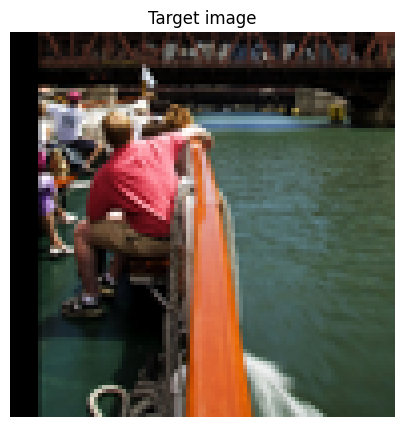

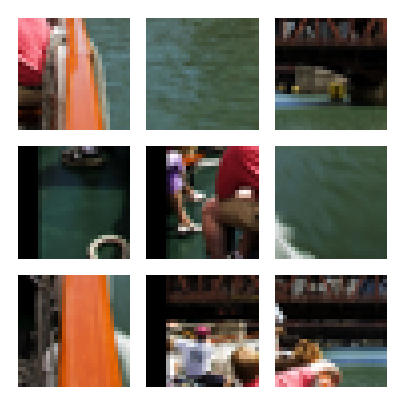

In [6]:
def plot_puzzle(patches, ordering=None):
    """
    Plots the 9 jigsaw patches on a 96x96 canvas.

    Args:
        patches: array of shape (9, 28, 28, 3)
        ordering: optional array of shape (9,) with the destination grid cells.
                  If it is not provided, the patches are displayed in their current order.
    """
    # 1. Handle ordering. If no order is given, keep the current patch order.
    if ordering is None:
        order = np.arange(NUM_PATCHES)
    else:
        order = np.array(ordering).flatten()

    # 2. Setup canvas. The model works with float images in [0, 1].
    if patches.dtype == np.uint8:
        canvas = np.full((HEIGHT, WIDTH, N_CHANNELS), 255, dtype=np.uint8)
    else:
        canvas = np.ones((HEIGHT, WIDTH, N_CHANNELS), dtype=np.float32)

    cell_dim = PATCH_SIZE
    patch_dim = CROP_SIZE
    margin = (cell_dim - patch_dim) // 2

    # 3. Place every patch into one cell of the 3x3 grid.
    for i in range(NUM_PATCHES):
        # Determine destination grid position.
        grid_pos = order[i]
        row = grid_pos // GRID_SIZE
        col = grid_pos % GRID_SIZE

        # Calculate canvas pixel coordinates.
        y_start = row * cell_dim + margin
        y_end = y_start + patch_dim
        x_start = col * cell_dim + margin
        x_end = x_start + patch_dim

        # Insert patch i into its grid position.
        canvas[y_start:y_end, x_start:x_end] = patches[i]

    # 4. Display the canvas.
    plt.figure(figsize=(5, 5))
    plt.imshow(np.clip(canvas, 0, 1))
    plt.axis('off')
    plt.show()


# Use a fixed example from the first test batch. This is the same qualitative
# example used during development, so the displayed image is reproducible.
example_patches, example_targets = test_generator[0]
example_images = get_image_targets(example_targets)

plt.figure(figsize=(5, 5))
plt.imshow(example_images[0])
plt.axis('off')
plt.title('Target image')
plt.show()

plot_puzzle(example_patches[0])


## The problem

Your task is to reconstruct the source (96, 96) image from the set of 9 scrambled patches of dimension (28, 28) each.

**The metric used to measure the quality of the reconstruction must be Mean Absolute Error (MAE).**

Compute MAE over the test set, and also return the standard deviation.


## Additional constraints

- The solution must rely entirely on neural networks and must not contain non-neural algorithmic components. A pipeline of neural networks is allowed.
- Pretrained models are not permitted.
- The total number of trainable parameters must remain below 6 million. The number of parameters of the proposed solution must be reported explicitly.
- The model weights must be made available for download via gdown. Please verify that the provided link works correctly and that the weights can be loaded successfully.
- The solution must be implemented in Keras and must run on Google Colab. Submissions containing notebook execution errors will be penalized.
- The submission must be a single, well documented notebook file. Tar files will be rejected.


## Development process

I did not start directly with the final model. First I ran smaller tests to make sure that the generator, the model output, the loss and the evaluation cell worked correctly. After that I increased the amount of data and the training time.

The first versions were useful but the reconstructions were quite blurry. In some runs the training error improved but the validation curve did not follow it, so I reduced that risk with data augmentation, batch normalization, dropout, weight decay and callbacks based on validation MAE.

I kept the objective as simple as possible: the model only learns from the image reconstruction loss. I did not add a position classifier or a label for the true permutation.


## Metrics

The official metric is Mean Absolute Error (MAE), computed between the predicted image and the target image. All pixels are normalized to [0, 1], so MAE is the average absolute pixel error over height, width and RGB channels.

For example, a MAE of 0.05 means that the average pixel-channel error is around 5% of the normalized range, approximately 0.05 * 255 = 12.75 gray levels in the original uint8 scale.

I also use MAE as the training loss because it is the evaluation criterion of the assignment. This makes the optimization objective consistent with the final test score. Therefore, in this model, the loss curve and the mae curve have the same interpretation. The final test cell reports the mean and standard deviation of the per-image MAE over the held-out test set.


## Baseline

The following mean-patch reconstruction is included only as a reference baseline. It is not used by the proposed neural solution.


In [7]:
def mean_patch_image(patches):
    # Simple reference reconstruction: average the 9 patches and repeat it.
    batch_size = tf.shape(patches)[0]
    # Average all input patches into one representative patch.
    mean_patch = tf.reduce_mean(patches, axis=1)
    mean_patches = tf.repeat(mean_patch[:, None, :, :, :], repeats=9, axis=1)
    # Reassemble the repeated patch into a 3x3 image and resize to 96x96.
    grid = tf.reshape(mean_patches, (batch_size, 3, 3, 28, 28, 3))
    grid = tf.transpose(grid, [0, 1, 3, 2, 4, 5])
    image_84 = tf.reshape(grid, (batch_size, 84, 84, 3))
    return tf.image.resize(image_84, (96, 96))


def evaluate_predict_fn(predict_fn, generator):
    sample_mae = []
    for i in range(len(generator)):
        patches, targets = generator[i]
        targets = get_image_targets(targets)
        preds = predict_fn(patches)
        batch_mae = tf.reduce_mean(tf.abs(preds - targets), axis=(1, 2, 3)).numpy()
        sample_mae.extend(batch_mae.tolist())
    return float(np.mean(sample_mae)), float(np.std(sample_mae))


baseline_mean, baseline_std = evaluate_predict_fn(mean_patch_image, test_generator)
print(f'Baseline test MAE: {baseline_mean:.6f}')
print(f'Baseline test MAE std: {baseline_std:.6f}')


Baseline test MAE: 0.182365
Baseline test MAE std: 0.056121


## Model overview

The complete reconstruction pipeline is:

scrambled patches
-> shared CNN patch encoder
-> patch self-attention
-> learned position queries + cross-attention
-> differentiable soft reassembly
-> U-Net refiner
-> reconstructed image

The first part is a shared CNN encoder because each input is an image patch and local spatial patterns are important. The encoder is shared across the 9 patches with TimeDistributed, so the model learns one common patch representation instead of nine independent encoders.

After convolutional feature extraction, global average pooling converts each patch into one feature token. This makes it possible to process the 9 patches as a short sequence. Self-attention is then useful because the reconstruction depends not only on each patch separately, but also on its relationship with the other patches.


## Neural reconstruction model

I separated the problem into two parts: first the network estimates where the visual information from the patches should go, and then a small refiner reconstructs a coherent image from that soft placement.

The model follows this structure:

1. A shared CNN extracts local features from each patch, such as color, texture, edges and simple shapes.
2. Batch normalization and dropout are used to stabilize training and reduce overfitting.
3. Self-attention lets the patch tokens compare themselves with the other patches. This is useful because one patch alone usually does not contain enough context to know its final position.
4. Learned position queries represent the 9 possible grid positions. Each position learns what kind of visual information it should attend to.
5. A differentiable reassembly layer creates a soft 96 x 96 canvas from the attention scores. This avoids using a hard permutation or an external puzzle-solving algorithm.
6. A small U-Net style refiner improves the final image and fills the missing borders. The skip connections help keep local detail while the bottleneck sees more global context.

This uses ideas from the course and lab material: CNNs for local image features, attention when tokens need context from each other, and U-Net style skip connections for image reconstruction. The reassembly is still part of the network. I am not matching borders with an external algorithm and I am not giving the true permutation to the model.

The tau value controls how sharp the softmax is in the reassembly layer. I start with a softer assignment and gradually reduce it during training, so the model can first learn in a smoother way and later make more confident placements.


In [8]:
class LearnedPositionQueries(layers.Layer):
    """Nine trainable query tokens, one for each output grid cell."""
    def __init__(self, num_queries=9, dim=192, **kwargs):
        super().__init__(**kwargs)
        self.num_queries = num_queries
        self.dim = dim

    def build(self, input_shape):
        self.queries = self.add_weight(
            name='queries',
            shape=(self.num_queries, self.dim),
            initializer='glorot_uniform',
            trainable=True,
        )

    def call(self, tokens):
        batch_size = tf.shape(tokens)[0]
        return tf.tile(self.queries[None, :, :], [batch_size, 1, 1])

    def get_config(self):
        config = super().get_config()
        config.update({'num_queries': self.num_queries, 'dim': self.dim})
        return config


class DifferentiablePatchReassembly(layers.Layer):
    """Attention-based differentiable patch reassembly on a 96x96 canvas.

    Inputs:
      patches : (B, 9, 28, 28, 3) scrambled patches
      scores  : (B, 9 output positions, 9 input patches) neural attention scores

    Outputs:
      canvas : (B, 96, 96, 3) soft assembled image
      mask   : (B, 96, 96, 1) 1 on patch interiors, 0 on missing seams

    `tau` is stored as a non-trainable weight so PlacementTemperatureCallback
    can update it each epoch without triggering a graph retrace.
    """
    def __init__(self, initial_tau=2.0, margin=2, **kwargs):
        super().__init__(**kwargs)
        self.initial_tau = initial_tau
        self.margin = margin

    def build(self, input_shape):
        self.tau = self.add_weight(
            name='tau',
            shape=(),
            initializer=tf.keras.initializers.Constant(self.initial_tau),
            trainable=False,
        )
        super().build(input_shape)

    def call(self, inputs):
        patches, scores = inputs
        weights = tf.nn.softmax(scores / self.tau, axis=-1)  # slot -> patch distribution
        placed = tf.einsum('bpijk,bsp->bsijk', patches, weights)

        m = self.margin
        cell = 28 + 2 * m

        # Put every 28x28 soft patch back into a 32x32 cell. The padded
        # regions correspond to the eroded borders that the refiner must infer.
        placed_32 = tf.pad(placed, [[0, 0], [0, 0], [m, m], [m, m], [0, 0]])
        grid = tf.reshape(placed_32, (-1, 3, 3, cell, cell, 3))
        grid = tf.transpose(grid, [0, 1, 3, 2, 4, 5])
        canvas = tf.reshape(grid, (-1, 96, 96, 3))

        # The mask tells the refiner which pixels come from the soft canvas
        # and which pixels correspond to missing borders/seams.
        mask_patch = tf.ones_like(placed[..., :1])
        mask_32 = tf.pad(mask_patch, [[0, 0], [0, 0], [m, m], [m, m], [0, 0]])
        mask_grid = tf.reshape(mask_32, (-1, 3, 3, cell, cell, 1))
        mask_grid = tf.transpose(mask_grid, [0, 1, 3, 2, 4, 5])
        mask = tf.reshape(mask_grid, (-1, 96, 96, 1))

        # The mask marks pixels that come directly from patch interiors.
        return canvas, mask

    def get_config(self):
        config = super().get_config()
        config.update({'initial_tau': self.initial_tau, 'margin': self.margin})
        return config


class PlacementTemperatureCallback(keras.callbacks.Callback):
    """Exponentially anneals the placement softmax temperature each epoch."""

    def __init__(self, initial_tau, final_tau, total_epochs):
        super().__init__()
        self.initial_tau = initial_tau
        self.final_tau = final_tau
        self.total_epochs = total_epochs

    def on_epoch_begin(self, epoch, logs=None):
        # Exponential annealing: early epochs use softer assignments, while
        # later epochs use sharper attention distributions.
        progress = epoch / max(self.total_epochs - 1, 1)
        new_tau = self.initial_tau * (self.final_tau / self.initial_tau) ** progress
        layer = self.model.get_layer('differentiable_patch_reassembly')
        layer.tau.assign(new_tau)
        print(f'  placement_tau = {new_tau:.4f}')


In [9]:
def conv_block(x, filters, name):
    x = layers.Conv2D(filters, 3, padding='same', activation='swish', name=f'{name}_conv1')(x)
    x = layers.BatchNormalization(name=f'{name}_bn1')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='swish', name=f'{name}_conv2')(x)
    x = layers.BatchNormalization(name=f'{name}_bn2')(x)
    return x


def small_unet_refiner(x):
    # Encoder-decoder refiner. Skip connections preserve spatial detail while
    # the bottleneck sees a larger image context.
    c1 = conv_block(x, 64, 'refine_down1')
    p1 = layers.MaxPooling2D(name='refine_pool1')(c1)

    c2 = conv_block(p1, 128, 'refine_down2')
    p2 = layers.MaxPooling2D(name='refine_pool2')(c2)

    c3 = conv_block(p2, 192, 'refine_bottleneck')
    c3 = layers.SpatialDropout2D(0.10, name='refine_bottleneck_dropout')(c3)

    u2 = layers.UpSampling2D(interpolation='bilinear', name='refine_up2')(c3)
    u2 = layers.Concatenate(name='refine_skip2')([u2, c2])
    c4 = conv_block(u2, 128, 'refine_upblock2')

    u1 = layers.UpSampling2D(interpolation='bilinear', name='refine_up1')(c4)
    u1 = layers.Concatenate(name='refine_skip1')([u1, c1])
    c5 = conv_block(u1, 64, 'refine_upblock1')

    return layers.Conv2D(3, 1, padding='same', activation='sigmoid', name='refined_pixels')(c5)


def get_model():
    # Input shape: 9 scrambled RGB patches.
    inputs = keras.Input(shape=(NUM_PATCHES, CROP_SIZE, CROP_SIZE, N_CHANNELS), name='scrambled_patches')

    # The same CNN encoder is applied to every patch with TimeDistributed.
    # This keeps the treatment of the 9 patches consistent.
    x = layers.TimeDistributed(layers.Conv2D(48, 3, padding='same', activation='relu'))(inputs)
    x = layers.TimeDistributed(layers.BatchNormalization())(x)
    x = layers.TimeDistributed(layers.MaxPooling2D())(x)

    x = layers.TimeDistributed(layers.Conv2D(96, 3, padding='same', activation='relu'))(x)
    x = layers.TimeDistributed(layers.BatchNormalization())(x)
    x = layers.TimeDistributed(layers.MaxPooling2D())(x)

    x = layers.TimeDistributed(layers.Conv2D(160, 3, padding='same', activation='relu'))(x)
    x = layers.TimeDistributed(layers.BatchNormalization())(x)
    x = layers.TimeDistributed(layers.Conv2D(160, 3, padding='same', activation='relu'))(x)
    x = layers.TimeDistributed(layers.BatchNormalization())(x)

    # One feature vector per patch. These 9 vectors are the tokens processed
    # by the attention blocks.
    tokens = layers.TimeDistributed(layers.GlobalAveragePooling2D())(x)
    tokens = layers.Dense(192, activation='relu')(tokens)
    tokens = layers.Dropout(0.10, name='token_dropout')(tokens)

    # Transformer-style encoder blocks over the 9 patch tokens.
    for block_idx in range(2):
        attn = layers.MultiHeadAttention(
            num_heads=4,
            key_dim=48,
            dropout=0.10,
            name=f'patch_self_attention_{block_idx + 1}',
        )(tokens, tokens)
        tokens = layers.Add()([tokens, attn])
        tokens = layers.LayerNormalization()(tokens)

        ff = layers.Dense(384, activation='relu')(tokens)
        ff = layers.Dropout(0.15)(ff)
        ff = layers.Dense(192)(ff)
        tokens = layers.Add()([tokens, ff])
        tokens = layers.LayerNormalization()(tokens)

    # Learned output-slot queries: one token for each final grid position.
    queries = LearnedPositionQueries(num_queries=NUM_PATCHES, dim=192, name='learned_position_queries')(tokens)
    cross = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=48,
        dropout=0.10,
        name='position_to_patch_cross_attention',
    )(queries, tokens)
    queries = layers.Add()([queries, cross])
    queries = layers.LayerNormalization(name='position_query_norm')(queries)

    # Neural attention scores: each output grid cell scores each input patch.
    # Dot-product scores between output-slot queries and input-patch tokens.
    # These scores are not labels; they are learned internal activations.
    scores = layers.Dot(axes=-1, name='position_patch_attention_scores')([queries, tokens])

    canvas, mask = DifferentiablePatchReassembly(
        initial_tau=PLACEMENT_TAU_INITIAL, name='differentiable_patch_reassembly'
    )([inputs, scores])

    # The refiner receives both the soft assembled canvas and the mask of
    # known/missing regions.
    refiner_input = layers.Concatenate(name='refiner_input')([canvas, mask])
    refined = small_unet_refiner(refiner_input)

    reconstructed = layers.Lambda(
        lambda t: tf.clip_by_value(t[1] * t[0] + (1.0 - t[1]) * t[2], 0.0, 1.0),
        output_shape=(HEIGHT, WIDTH, N_CHANNELS),
        name='reconstructed_image',
    )([canvas, mask, refined])

    return keras.Model(
        inputs=inputs,
        outputs=reconstructed,
        name='cnn_attention_reassembly_unet_reconstructor',
    )


def build_patch_reconstruction_model():
    return get_model()


model = get_model()
model.summary()

param_count = model.count_params()
print('Trainable parameters:', f'{param_count:,}')
assert param_count < 6_000_000, 'Model exceeds 6 million parameters.'
print('Parameter budget OK (< 6,000,000).')


Model: "cnn_attention_reassembly_unet_reconstructor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ scrambled_patches   │ (None, 9, 28, 28, │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 9, 28, 28, │      1,344 │ scrambled_patche… │
│ (TimeDistributed)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_1  │ (None, 9, 28, 28, │        192 │ time_distributed… │
│ (TimeDistributed)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_2  │ (None, 9, 14, 14, │          0 │ time_distributed… │
│ (TimeDistributed)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_3  │ (None, 9, 14, 14, │     41,568 │ time_distributed… │
│ (TimeDistributed)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_4  │ (None, 9, 14, 14, │        384 │ time_distributed… │
│ (TimeDistributed)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_5  │ (None, 9, 7, 7,   │          0 │ time_distributed… │
│ (TimeDistributed)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_6  │ (None, 9, 7, 7,   │    138,400 │ time_distributed… │
│ (TimeDistributed)   │ 160)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_7  │ (None, 9, 7, 7,   │        640 │ time_distributed… │
│ (TimeDistributed)   │ 160)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_8  │ (None, 9, 7, 7,   │    230,560 │ time_distributed… │
│ (TimeDistributed)   │ 160)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_9  │ (None, 9, 7, 7,   │        640 │ time_distributed… │
│ (TimeDistributed)   │ 160)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_10 │ (None, 9, 160)    │          0 │ time_distributed… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 9, 192)    │     30,912 │ time_distributed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_dropout       │ (None, 9, 192)    │          0 │ dense[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_self_attenti… │ (None, 9, 192)    │    148,224 │ token_dropout[0]… │
│ (MultiHeadAttentio… │                   │            │ token_dropout[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 9, 192)    │          0 │ token_dropout[0]… │
│                     │                   │            │ patch_self_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 9, 192)    │        384 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 2,671,844 (10.19 MB)

 Trainable params: 2,668,611 (10.18 MB)

 Non-trainable params: 3,233 (12.63 KB)

Trainable parameters: 2,671,844
Parameter budget OK (< 6,000,000).


## Training

The model is trained only with image reconstruction MAE. There is no extra output for the patch order.

I use AdamW because it worked better in my intermediate tests than plain Adam and it adds weight decay directly in the optimizer. Together with augmentation, dropout and batch normalization, it helps control overfitting.

The training cell is controlled with TRAIN_MODEL. For the submitted version I keep it as False, load the saved final weights, and run the test evaluation directly. If I need to retrain the model, I can set it to True.

When training is active, I monitor val_mae. ReduceLROnPlateau lowers the learning rate when validation stops improving, and EarlyStopping avoids spending too many epochs when the validation error is no longer improving.


In [10]:
# AdamW worked well in the intermediate runs and adds weight decay.
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
    loss='mae',
    metrics=[keras.metrics.MeanAbsoluteError(name='mae')],
)

history = None

if TRAIN_MODEL:
    print('Training from scratch.')

    # The official objective is MAE, so the checkpoint is selected using val_mae.
    MONITOR = 'val_mae'

    callbacks = [
        PlacementTemperatureCallback(
            initial_tau=PLACEMENT_TAU_INITIAL,
            final_tau=PLACEMENT_TAU_FINAL,
            total_epochs=EPOCHS,
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(WEIGHTS_PATH),
            monitor=MONITOR,
            mode='min',
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor=MONITOR,
            mode='min',
            factor=0.5,
            patience=5,
            min_lr=1e-5,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor=MONITOR,
            mode='min',
            patience=14,
            restore_best_weights=True,
            verbose=1,
        ),
    ]

    # history stores the training and validation curves plotted in the next cell.
    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        callbacks=callbacks,
    )

    model.save_weights(WEIGHTS_PATH)
    print(f'Final weights saved to: {WEIGHTS_PATH}')
else:
    print('Training skipped. Set TRAIN_MODEL = True only to retrain the model.')


Training skipped. Set TRAIN_MODEL = True only to retrain the model.


In [11]:
# Training curves
if history is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history['loss'], label='train')
    axes[0].plot(history.history['val_loss'], label='val')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('epoch')
    axes[0].legend()

    axes[1].plot(history.history['mae'], label='train')
    axes[1].plot(history.history['val_mae'], label='val')
    axes[1].set_title('Reconstruction MAE')
    axes[1].set_xlabel('epoch')
    axes[1].legend()

    plt.tight_layout()
    plt.show()
else:
    print('No training history in this execution because TRAIN_MODEL = False.')


No training history in this execution because TRAIN_MODEL = False.


## Interpreting the training curves

The plots above are mainly a check that the model is learning and not just memorizing the training batches.

The training curve is computed on augmented training data. The validation curve is computed on images that are not used to update the weights. If the training MAE keeps going down but validation MAE gets stuck or increases for many epochs, that would suggest overfitting.

Some small validation jumps are normal. I focus more on the general trend and on the best validation MAE, because that is the checkpoint used later for the test set.


## Reload weights with gdown

This is the reproducibility check. The notebook downloads the submitted weights from the public Drive file with gdown, builds a fresh copy of the model, loads the downloaded weights, and runs a small reload check before the final test evaluation.

This is the same idea as saving weights, sharing the file id, and reloading the model from gdown in a clean runtime.


In [ ]:
# Reload weights from gdown, for reproducibility.
# The file is shared publicly and can be downloaded without mounting Google Drive.

try:
    import gdown
except ImportError:
    import subprocess
    subprocess.run(['pip', '-q', 'install', '--upgrade', 'gdown'], check=True)
    import gdown

GDRIVE_FILE_ID = '1QtM8X3xJ8UvQT2IOK5pu8nk_pjYdeXam'
gdown_url = f'https://drive.google.com/uc?id={GDRIVE_FILE_ID}'
print(f'gdown download link: {gdown_url}')

gdown.download(gdown_url, DOWNLOADED_WEIGHTS_PATH, quiet=False)

# Build a fresh copy of the model and load the downloaded weights.
# If this works, the downloaded weights match the architecture in this notebook.
model_reload = get_model()
model_reload.load_weights(DOWNLOADED_WEIGHTS_PATH)

# Quick check on one batch before using the reloaded model for the full test.
a_check, b_check = test_generator.__getitem__(0)
pred_check = model_reload.predict(a_check[:1], verbose=0)
pred_check = pred_check['reconstructed_image'] if isinstance(pred_check, dict) else pred_check
reload_mae = tf.reduce_mean(tf.abs(pred_check - b_check[:1]))
print('Reload check MAE:', float(reload_mae))

# Use the reloaded model for the final evaluation below.
model = model_reload
print('Submitted weights downloaded with gdown and loaded successfully.')


## Final test evaluation

Here I compute the final MAE on the held-out test split, using the same evaluation style as the provided starter notebook. The test set is not used for training or for choosing any training callback.


In [ ]:
# Compute MAE over the test_generator, following the style of the provided notebook.
mae = tf.keras.metrics.MeanAbsoluteError()
mae_values = []

for i in range(len(test_generator)):
    a, b = test_generator.__getitem__(i)
    pred = model.predict(a, verbose=0)
    pred = pred['reconstructed_image'] if isinstance(pred, dict) else pred
    mae_values.append(mae(b, pred))

print('MAE:', tf.reduce_mean(mae_values))
print('std:', tf.math.reduce_std(mae_values))
print('Trainable parameters:', f'{model.count_params():,}')


## Qualitative reconstruction examples

I show a few examples from a later test batch instead of always using the first batch. This does not affect the metric; it only changes which images are shown for visual inspection.


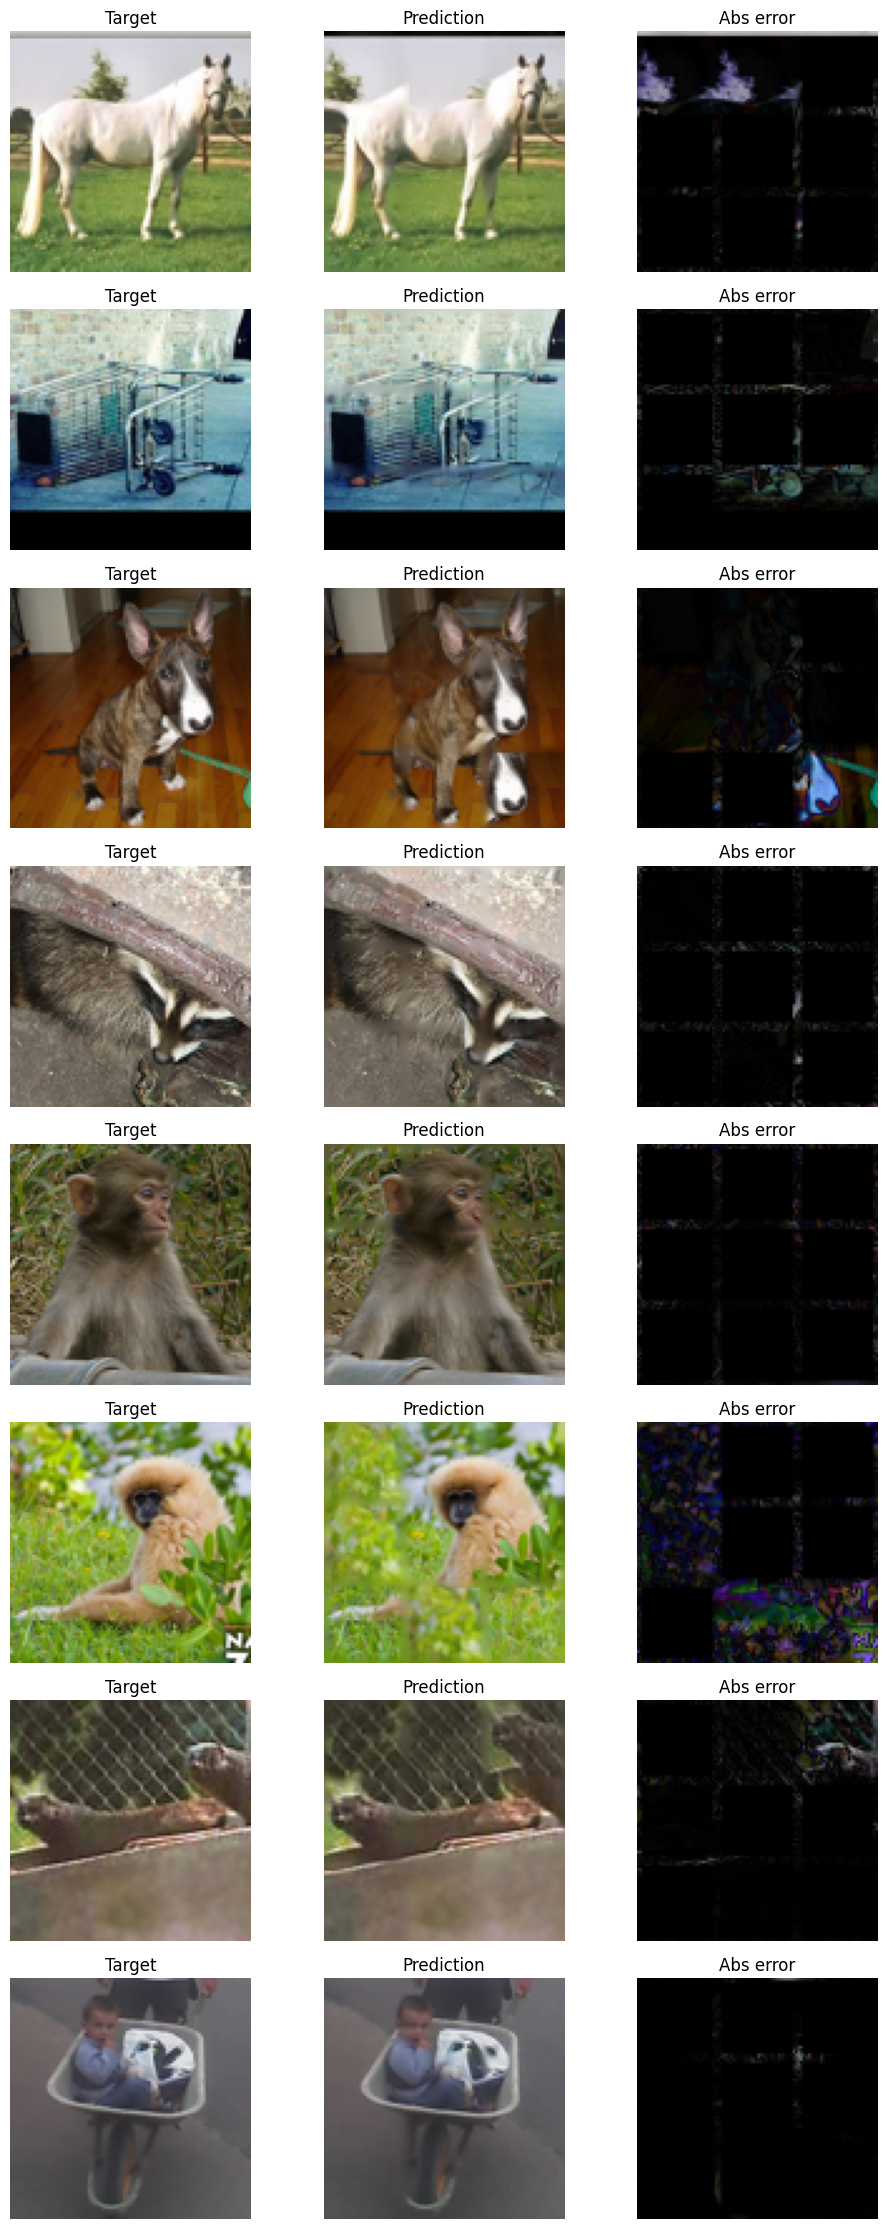

In [18]:
EXAMPLE_BATCH = 10
N_EXAMPLES = 8

patches, targets = test_generator[EXAMPLE_BATCH]
targets = get_image_targets(targets)
preds = model.predict(patches[:N_EXAMPLES], verbose=0)
preds = preds['reconstructed_image'] if isinstance(preds, dict) else preds

plt.figure(figsize=(10, 2.8 * N_EXAMPLES))
for i in range(N_EXAMPLES):
    plt.subplot(N_EXAMPLES, 3, 3 * i + 1)
    plt.imshow(targets[i])
    plt.axis('off')
    plt.title('Target')

    plt.subplot(N_EXAMPLES, 3, 3 * i + 2)
    plt.imshow(np.clip(preds[i], 0, 1))
    plt.axis('off')
    plt.title('Prediction')

    plt.subplot(N_EXAMPLES, 3, 3 * i + 3)
    plt.imshow(np.abs(preds[i] - targets[i]))
    plt.axis('off')
    plt.title('Abs error')

plt.tight_layout()
plt.show()

## Summary

The final model gives a much better reconstruction than the initial simple baseline. The images are not perfect, because the task is ambiguous and the patch borders are missing, but the predictions usually recover the main colors, objects and global layout much better than a naive average-patch reconstruction.

I tried to keep the solution simple to justify: the network does not receive the true permutation, it stays below the 6M parameter limit, and the reconstruction is learned end to end from MAE. During development I first used small runs to check that the pipeline worked, then increased the amount of data and the number of epochs while monitoring validation MAE. The final validation behaviour did not show a clear overfitting gap, so I consider the result solid for this setup.
